<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 5 · Sesión 2: CatBoost: árboles simétricos, regularización, benchmarks e innovaciones</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: árbol simétrico desde el JSON, hiperparámetros, monotonicidad, calibración, SHAP, comparación con XGBoost; embeddings, texto y graph features</div>
</div>

## Objetivos de la sesión (2 horas)

1. **Árboles simétricos (oblivious)**: estructura, predicción por índice binario y por qué regularizan y aceleran la inferencia.
2. **Hiperparámetros y regularización** de CatBoost: `depth`, `l2_leaf_reg`, `random_strength`, `bagging_temperature`, `border_count`, `grow_policy`, `one_hot_max_size`.
3. CatBoost para PD: **restricciones monotónicas**, calibración y valores SHAP.
4. **Comparación** con XGBoost y con el scorecard fuera de tiempo, incluido el tiempo de entrenamiento y de predicción.
5. **Benchmarks independientes** XGBoost vs. CatBoost (paper original, TabZilla, Florek y Zagdański, TabArena).
6. **Innovaciones 2022-2026**: variables de **embeddings**, de **texto** y **graph aggregated features** (1.2.6), multiquantile, Polars, entre otras.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Árboles simétricos |
| 2 | 25 min | Hiperparámetros y regularización |
| 3 | 20 min | CatBoost para PD y comparación |
| 4 | 15 min | Benchmarks |
| 5 | 30 min | Embeddings, texto y grafos |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import time, json, xgboost as xgb, catboost
from catboost import CatBoostClassifier, Pool
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss
print("CatBoost", catboost.__version__, "| XGBoost", xgb.__version__)
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, np.nan, -app.DAYS_EMPLOYED / 365.25)
app["PENSIONISTA"] = (app.DAYS_EMPLOYED == 365243).astype(int)
NUM = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "ANTIG", "PENSIONISTA", "AMT_INCOME_TOTAL", "AMT_CREDIT",
       "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT", "CNT_CHILDREN"]
CAT = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "CANAL", "ORGANIZATION_TYPE", "AGENCIA_ID", "EMPLEADOR_ID", "COMERCIO_ALIADO"]
for c in CAT: app[c] = app[c].fillna("Sin dato").astype(str)
F = NUM + CAT
tr = app[app.FECHA_SOLICITUD < "2024-01"].reset_index(drop=True)
va = app[(app.FECHA_SOLICITUD >= "2024-01") & (app.FECHA_SOLICITUD < "2025-01")].reset_index(drop=True)
te = app[app.FECHA_SOLICITUD >= "2025-01"].reset_index(drop=True)
yt = te.TARGET.values
pool = lambda d, cols=F: Pool(d[cols], d.TARGET, cat_features=[c for c in cols if c in CAT])
BASE = dict(iterations=3000, learning_rate=0.08, depth=6, od_type="Iter", od_wait=100, verbose=0, random_seed=0, allow_writing_files=False)
print(f"entrenamiento: {len(tr):,} | validación: {len(va):,} | prueba: {len(te):,}")

CatBoost 1.2.10 | XGBoost 3.4.1


entrenamiento: 30,039 | validación: 15,053 | prueba: 14,908


## 1. Árboles simétricos (oblivious trees)

CatBoost usa por defecto árboles **simétricos**: en cada nivel **todas** las ramas usan la **misma** partición (variable y umbral). Un árbol de profundidad $d$ queda definido por $d$ condiciones y $2^d$ hojas, y la hoja de un cliente es un **número binario**:

$$\text{hoja}(x) = \sum_{l=0}^{d-1} 2^{l}\, \mathbb{1}\{x_{j_l} > b_l\}$$

| Propiedad | Consecuencia |
|---|---|
| Misma partición en todo el nivel | El árbol es una **tabla de decisión**: menos flexible, **menos sobreajuste** (regularización estructural) |
| Hoja = índice binario | Predicción sin ramificaciones: comparaciones vectorizadas, muy rápida en CPU y GPU |
| Elección de la partición | Se elige la que minimiza la pérdida **sumada en todas las hojas** del nivel |
| Alternativas | `grow_policy="Depthwise"` (como XGBoost) o `"Lossguide"` (hoja a hoja, como LightGBM) |

Reproducimos un árbol de CatBoost leyendo el modelo exportado en JSON:

In [2]:
N3 = ["EXT_SOURCE_2", "EDAD", "RCI"]
m3 = CatBoostClassifier(iterations=50, depth=3, learning_rate=0.3, verbose=0, random_seed=0, allow_writing_files=False).fit(tr[N3], tr.TARGET)
import tempfile, os
ruta = os.path.join(tempfile.gettempdir(), "arbol_catboost.json"); m3.save_model(ruta, format="json"); J = json.load(open(ruta))
t0 = J["oblivious_trees"][0]
for l, s in enumerate(t0["splits"]):
    print(f"nivel {l}: {N3[s['float_feature_index']]} > {s['border']:.4f}   (peso 2^{l} = {2 ** l})")
hojas = pd.DataFrame({"hoja": range(8), "valor": t0["leaf_values"], "peso (casos)": t0["leaf_weights"]})
display(hojas.style.format({"valor": "{:+.4f}", "peso (casos)": "{:,.0f}"}))
X = te[N3].values; idx = np.zeros(len(X), int)
for l, s in enumerate(t0["splits"]): idx += (X[:, s["float_feature_index"]] > s["border"]).astype(int) << l
propio = np.array(t0["leaf_values"])[idx]
cb = m3.predict(te[N3], prediction_type="RawFormulaVal", ntree_end=1) - J["scale_and_bias"][1][0]
print("Predicción del primer árbol por índice binario = CatBoost:", np.allclose(propio, cb))

nivel 0: EXT_SOURCE_2 > 0.3925   (peso 2^0 = 1)
nivel 1: RCI > 1.3650   (peso 2^1 = 2)
nivel 2: RCI > 0.6467   (peso 2^2 = 4)


,hoja,valor,peso (casos)
0,0,-0.3460,"3,848"
1,1,-0.5266,"21,848"
2,2,+0.0000,0
3,3,+0.0000,0
4,4,-0.2505,733
5,5,-0.4758,"2,905"
6,6,-0.1655,162
7,7,-0.3946,543


Predicción del primer árbol por índice binario = CatBoost: True


**Lectura:** tres condiciones definen las 8 hojas. Algunas combinaciones pueden quedar vacías o con muy pocos casos (por ejemplo, condiciones sobre la misma variable en dos niveles): es el precio de la simetría. A cambio, la predicción es un cálculo de bits.

### Velocidad de predicción

In [3]:
big = pd.concat([te] * 20, ignore_index=True)             # ~300 000 solicitudes
mcb = CatBoostClassifier(iterations=500, depth=6, learning_rate=0.08, verbose=0, random_seed=0, allow_writing_files=False).fit(pool(tr, NUM))
mx = xgb.XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.08, tree_method="hist").fit(tr[NUM], tr.TARGET)
tiempos = {}
for nombre, f in [("CatBoost (simétrico, prof. 6)", lambda: mcb.predict_proba(big[NUM])), ("XGBoost (prof. 6)", lambda: mx.predict_proba(big[NUM]))]:
    f(); t0_ = time.time(); [f() for _ in range(3)]; tiempos[nombre] = (time.time() - t0_) / 3
pd.Series(tiempos, name=f"segundos para predecir {len(big):,} solicitudes (500 árboles)").to_frame().style.format("{:.3f}")

,"segundos para predecir 298,160 solicitudes (500 árboles)"
"CatBoost (simétrico, prof. 6)",0.082
XGBoost (prof. 6),1.700


**Lectura:** con el mismo número de árboles y profundidad, la predicción de CatBoost suele ser más rápida que la de XGBoost en CPU: es la ventaja de evaluar condiciones idénticas por nivel. En originación digital (respuesta en milisegundos) y en el recálculo masivo de la cartera para provisiones, la velocidad de inferencia importa.

## 2. Hiperparámetros y regularización

| Parámetro | Qué hace | Valor por defecto |
|---|---|---|
| `depth` | Profundidad del árbol simétrico ($2^d$ hojas) | 6 |
| `l2_leaf_reg` | Penalización L2 de los valores de las hojas (como λ en XGBoost) | 3 |
| `random_strength` | Ruido en el puntaje de las particiones candidatas: evita elegir siempre la misma | 1 |
| `bootstrap_type` / `bagging_temperature` | Remuestreo de cada árbol. Por defecto en CPU es **MVS** (muestreo por varianza mínima, guiado por los gradientes). Con `"Bayesian"`, pesos $w_i = (-\log U_i)^t$: $t = 0$ sin remuestreo, $t = 1$ pesos exponenciales | MVS; $t$ = 1 |
| `border_count` | Número de umbrales candidatos por variable numérica (cuantización) | 254 en CPU |
| `one_hot_max_size` | Categóricas con hasta ese número de niveles van con one-hot; el resto con CTR | 2 |
| `grow_policy` | `SymmetricTree`, `Depthwise`, `Lossguide` | SymmetricTree |
| `learning_rate` | Se ajusta automáticamente según el tamaño de los datos si no se fija | auto |

Probamos cada parámetro alrededor de la configuración base (validación 2024 para early stopping, prueba 2025):

In [4]:
grid = {"base (prof. 6, l2 = 3)": {}, "profundidad 4": {"depth": 4}, "profundidad 8": {"depth": 8},
        "l2_leaf_reg = 30": {"l2_leaf_reg": 30}, "random_strength = 0": {"random_strength": 0}, "random_strength = 5": {"random_strength": 5},
        "Bayesian, temperatura 0": {"bootstrap_type": "Bayesian", "bagging_temperature": 0}, "Bayesian, temperatura 5": {"bootstrap_type": "Bayesian", "bagging_temperature": 5},
        "border_count = 32": {"border_count": 32}, "grow_policy = Depthwise": {"grow_policy": "Depthwise"}, "grow_policy = Lossguide": {"grow_policy": "Lossguide"},
        "one_hot_max_size = 255": {"one_hot_max_size": 255}}
filas = []
for nombre, extra in grid.items():
    t0_ = time.time(); m = CatBoostClassifier(**{**BASE, **extra}).fit(pool(tr), eval_set=pool(va), use_best_model=True)
    p = m.predict_proba(te[F])[:, 1]
    filas.append({"configuración": nombre, "árboles": m.get_best_iteration(), "log-loss valid.": m.get_best_score()["validation"]["Logloss"],
                  "AUC 2025": roc_auc_score(yt, p), "segundos": time.time() - t0_})
res_grid = pd.DataFrame(filas).set_index("configuración")
display(res_grid.style.format({"árboles": "{:.0f}", "log-loss valid.": "{:.4f}", "AUC 2025": "{:.4f}", "segundos": "{:.1f}"}).background_gradient(subset=["AUC 2025"], cmap="Greens"))

,árboles,log-loss valid.,AUC 2025,segundos
configuración,,,,
"base (prof. 6, l2 = 3)",214,0.2235,0.7920,12.1
profundidad 4,391,0.2235,0.7942,12.4
profundidad 8,150,0.2241,0.7936,14.5
l2_leaf_reg = 30,382,0.2231,0.7952,17.5
random_strength = 0,227,0.2247,0.7915,12.5
random_strength = 5,315,0.2235,0.7913,14.7
"Bayesian, temperatura 0",256,0.2235,0.7944,13.9
"Bayesian, temperatura 5",644,0.2259,0.7887,29.8
border_count = 32,225,0.2236,0.7934,11.8


**Lectura:** CatBoost es poco sensible a sus hiperparámetros: todas las variaciones quedan dentro de unos ±0,4 puntos de AUC. Es una de sus fortalezas más citadas (y la razón por la que en benchmarks rinde bien *sin tuning*). Más regularización L2 ayuda un poco; los árboles no simétricos (`Depthwise`, `Lossguide`) entrenan más rápido pero rinden algo menos, coherente con el efecto regularizador de la simetría; y `one_hot_max_size` alto empeora: pasar AGENCIA_ID (180 niveles) a one-hot desperdicia la información que las CTR capturan.

## 3. CatBoost para PD: monotonicidad, calibración y SHAP

CatBoost sin restricciones  AUC 2025 = 0.7920
CatBoost monotónico         AUC 2025 = 0.7890


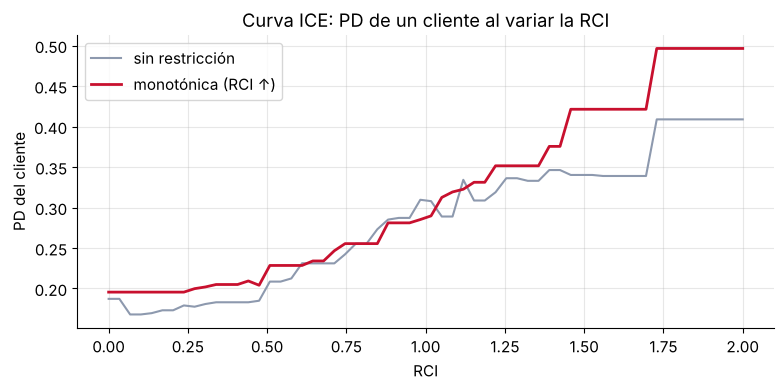

In [5]:
mono = {"EXT_SOURCE_1": -1, "EXT_SOURCE_2": -1, "EXT_SOURCE_3": -1, "RCI": 1}
m_mono = CatBoostClassifier(**BASE, monotone_constraints=mono).fit(pool(tr), eval_set=pool(va), use_best_model=True)
m_libre = CatBoostClassifier(**BASE).fit(pool(tr), eval_set=pool(va), use_best_model=True)
for nombre, m in [("sin restricciones", m_libre), ("monotónico", m_mono)]:
    print(f"CatBoost {nombre:18s} AUC 2025 = {roc_auc_score(yt, m.predict_proba(te[F])[:, 1]):.4f}")
# curva ICE de un cliente al variar la RCI
cli = te.iloc[[7]].copy(); rci = np.linspace(0, 2, 60); rep = pd.concat([cli] * 60, ignore_index=True); rep["RCI"] = rci
plt.figure(figsize=(9, 3.8))
plt.plot(rci, m_libre.predict_proba(rep[F])[:, 1], color=GRIS, label="sin restricción"); plt.plot(rci, m_mono.predict_proba(rep[F])[:, 1], color=ROJO, lw=2, label="monotónica (RCI ↑)")
plt.xlabel("RCI"); plt.ylabel("PD del cliente"); plt.legend(); plt.title("Curva ICE: PD de un cliente al variar la RCI"); plt.show()

In [6]:
# calibración: ajustar en el 1S-2025 y evaluar en el 2S-2025, como en los Módulos 3 y 4
s1, s2 = te.FECHA_SOLICITUD < "2025-07", te.FECHA_SOLICITUD >= "2025-07"
raw = m_mono.predict(te[F], prediction_type="RawFormulaVal")
platt = LogisticRegression(C=1e6).fit(raw[s1].reshape(-1, 1), yt[s1])
p_orig, p_cal = m_mono.predict_proba(te[F])[:, 1], platt.predict_proba(raw.reshape(-1, 1))[:, 1]
pd.DataFrame({"PD media": [p_orig[s2].mean(), p_cal[s2].mean()], "tasa observada": [yt[s2].mean()] * 2,
              "log-loss": [log_loss(yt[s2], p_orig[s2]), log_loss(yt[s2], p_cal[s2])], "AUC": [roc_auc_score(yt[s2], p_orig[s2]), roc_auc_score(yt[s2], p_cal[s2])]},
             index=["CatBoost monotónico", "+ Platt"]).style.format({"PD media": "{:.2%}", "tasa observada": "{:.2%}", "log-loss": "{:.4f}", "AUC": "{:.4f}"})

,PD media,tasa observada,log-loss,AUC
CatBoost monotónico,8.28%,5.91%,0.1912,0.8013
+ Platt,5.57%,5.91%,0.1867,0.8013


In [7]:
shap = m_mono.get_feature_importance(pool(te.iloc[:3]), type="ShapValues")      # última columna = valor esperado
contrib = pd.DataFrame(shap[:, :-1].T, index=F, columns=["cliente 1", "cliente 2", "cliente 3"])
print("Suma de SHAP + base = log-odds predicho:", np.allclose(shap.sum(1), m_mono.predict(te[F].iloc[:3], prediction_type="RawFormulaVal")))
contrib.loc[contrib.abs().max(axis=1).sort_values(ascending=False).index[:8]].style.format("{:+.3f}")

Suma de SHAP + base = log-odds predicho: True


,cliente 1,cliente 2,cliente 3
EXT_SOURCE_2,+0.225,-0.871,+0.122
EMPLEADOR_ID,-0.047,-0.321,+0.340
EXT_SOURCE_3,+0.304,+0.282,-0.079
NAME_INCOME_TYPE,+0.113,+0.110,-0.256
NAME_EDUCATION_TYPE,-0.225,-0.182,-0.191
REGION_RATING_CLIENT,-0.037,+0.183,-0.178
EDAD,-0.043,-0.109,-0.174
ANTIG,+0.010,-0.127,+0.099


**Lectura:** las mismas herramientas de gobierno del Módulo 4 existen en CatBoost: restricciones monotónicas (aquí cuestan unos 0,3 puntos de AUC a cambio de un comportamiento defendible), recalibración del nivel de la PD para un año más benigno y SHAP exacto con la propiedad de aditividad. Las categóricas de alta cardinalidad (EMPLEADOR_ID, AGENCIA_ID) aparecen directamente como contribuciones, lo que facilita las razones de rechazo.

### Comparación final fuera de tiempo

In [8]:
filas = []
def reg(nombre, p, seg):
    filas.append({"modelo": nombre, "AUC 2025": roc_auc_score(yt, p), "Gini": 2 * roc_auc_score(yt, p) - 1, "log-loss": log_loss(yt, p), "segundos": seg})
t0_ = time.time(); m = CatBoostClassifier(**BASE).fit(pool(tr), eval_set=pool(va), use_best_model=True); reg("CatBoost (categóricas en bruto)", m.predict_proba(te[F])[:, 1], time.time() - t0_)
reg("CatBoost monotónico", m_mono.predict_proba(te[F])[:, 1], np.nan)
t0_ = time.time(); m = CatBoostClassifier(**BASE).fit(pool(tr, NUM), eval_set=pool(va, NUM), use_best_model=True); reg("CatBoost solo numéricas", m.predict_proba(te[NUM])[:, 1], time.time() - t0_)
xc = lambda d: d[F].assign(**{c: pd.Categorical(d[c], categories=sorted(app[c].unique())) for c in CAT})
t0_ = time.time()
mx = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=100,
                       eval_metric="logloss", enable_categorical=True).fit(xc(tr), tr.TARGET, eval_set=[(xc(va), va.TARGET)], verbose=False)
reg("XGBoost (categóricas nativas)", mx.predict_proba(xc(te))[:, 1], time.time() - t0_)
comp = pd.DataFrame(filas).set_index("modelo")
comp.loc["Scorecard logístico (Módulo 3)"] = [0.7716, 0.5432, 0.1973, np.nan]
comp.style.format({"AUC 2025": "{:.4f}", "Gini": "{:.4f}", "log-loss": "{:.4f}", "segundos": "{:.1f}"}, na_rep="—")

,AUC 2025,Gini,log-loss,segundos
modelo,,,,
CatBoost (categóricas en bruto),0.7920,0.5839,0.1919,11.3
CatBoost monotónico,0.7890,0.5780,0.1933,—
CatBoost solo numéricas,0.7514,0.5029,0.2031,0.8
XGBoost (categóricas nativas),0.7751,0.5502,0.1961,2.7
Scorecard logístico (Módulo 3),0.7716,0.5432,0.1973,—


**Lectura:** sin las categóricas de alta cardinalidad, CatBoost queda en el nivel del scorecard y de XGBoost (~0,77). La ventaja de **~2 puntos de AUC** viene casi entera de extraer información de empleador, agencia y comercio con target statistics ordenadas. Si una cartera no tiene categóricas ricas, no hay que esperar milagros; si las tiene, CatBoost es la forma más segura de aprovecharlas.

## 4. Benchmarks independientes: XGBoost vs. CatBoost

| Estudio | Alcance | Resultado principal |
|---|---|---|
| **Prokhorenkova et al. (NeurIPS 2018)**, tabla 2 | 9 datasets, muchos con categóricas | CatBoost gana en todos: XGBoost tiene +17 % de log-loss en Amazon, +11 % en Epsilon, +7,9 % en KDD Internet, +3,2 % en Kick |
| **McElfresh et al. (NeurIPS 2023), "When Do Neural Nets Outperform Boosted Trees on Tabular Data?"** (TabZilla) | 19 algoritmos, 176 datasets (tabla 1: 98 datasets) | Rango medio: **CatBoost 5,50**, TabPFN 5,89, XGBoost 6,87, ResNet 7,65, RandomForest 8,26, LightGBM 8,46. Un ligero tuning del GBDT importa más que elegir entre GBDT y redes |
| **Florek y Zagdański (2023), arXiv 2305.17094** | 12 datasets; GBM, XGBoost, LightGBM, CatBoost con y sin tuning | Sin tuning, **XGBoost y CatBoost** son los mejores en AUC; con tuning, LightGBM es el más consistente y rápido. El tuning no mejora significativamente a CatBoost ni a XGBoost |
| **Erickson et al., TabArena (NeurIPS 2025)** | 51 datasets curados, 16 modelos | **CatBoost primero con tuning estándar** (sin ensembles); con ensembles *post-hoc*: TabM 1.º, LightGBM 2.º, RealMLP 3.º, CatBoost 4.º, XGBoost 5.º |
| Paper original, tabla 6 | Tiempo por árbol en Epsilon | CatBoost Plain 1,1 s, Ordered 1,9 s, XGBoost 3,9 s, LightGBM 1,1 s |

**Lectura de conjunto:**
1. CatBoost es consistentemente uno de los mejores modelos **con configuración por defecto o tuning ligero**: es robusto.
2. Su ventaja es mayor cuando hay **categóricas** (Amazon, Kick, KDD); en datos puramente numéricos las diferencias con XGBoost y LightGBM son pequeñas.
3. No hay un ganador universal: con tuning intensivo y ensembles, otros modelos lo alcanzan. El costo de tuning y el gobierno del modelo cuentan tanto como un punto de AUC.

## 5. Innovaciones recientes de la librería (2022-2026)

| Versión (fecha) | Innovación | Uso en riesgo de crédito |
|---|---|---|
| **1.1** (sep. 2022) | Regresión **multiquantile**; variables de **texto y embeddings** para regresión y ranking | Cuantiles de LGD o ingreso en un solo modelo |
| **1.1.1** (nov. 2022) | Embeddings en el aplicador C/C++; API tipo DataFrame de Spark para `Pool` | Despliegue de modelos con embeddings |
| **1.2** (may. 2023) | **Focal loss**; `RMSEWithUncertainty` en GPU; MultiLogloss con texto; build con CMake | Eventos raros (fraude); incertidumbre de la predicción |
| **1.2.1** (ago. 2023) | **Kernel gradient boosting** (`sample_gaussian_process`); MultiRMSE en GPU | Muestreo de modelos para incertidumbre |
| **1.2.3** (feb. 2024) | Python 3.12, Spark 3.5, **target booleano** | — |
| **1.2.5** (abr. 2024) | Métricas personalizadas en GPU; correcciones de texto y embeddings en GPU | — |
| **1.2.6** (sep. 2024) | **Graph aggregated features**; objetivos y métricas personalizadas en GPU; métrica `GroupQuantile` | Información de redes de clientes |
| **1.2.8** (abr. 2025) | Python 3.13 y **NumPy 2** | Compatibilidad del stack |
| **1.2.9** (feb. 2026) | Entrada nativa **Polars**; Python 3.14; carga del modelo *zero-copy* (mmap); Lossguide más rápido | Pipelines modernos; servicio de baja latencia |
| **1.2.10** (feb. 2026) | **Spark 4.0 y 4.1**; `predictTransposed` en JVM | Scoring masivo distribuido |

*Fuente: notas de versión de CatBoost en GitHub y documentación en catboost.ai.*

### 5.1 Variables de embeddings

Un **embedding** es un vector denso que resume información compleja: el historial de transacciones de un cliente, la descripción de su negocio, la imagen de un documento. CatBoost acepta columnas cuyo valor es un vector (`embedding_features`) y calcula sobre ellas, con el mismo esquema ordenado:
- **LDA**: proyección discriminante lineal del vector sobre las direcciones que mejor separan las clases;
- **KNN**: número de vecinos de cada clase entre los $k$ más cercanos (entre los casos anteriores en la permutación).

Simulamos un **embedding de 8 dimensiones del comportamiento transaccional** (por ejemplo, salido de un autoencoder sobre los movimientos de la cuenta). La simulación incluye una señal de riesgo débil que no está en las demás variables.

In [9]:
rng = np.random.default_rng(11); Amix = np.random.default_rng(3).normal(0, 1, (4, 8))
def embedding(d):
    u = 0.5 * (d.TARGET.values - 0.08) / 0.27 + rng.normal(0, 1, len(d))       # señal débil + ruido (simulación)
    return list(np.c_[u, rng.normal(0, 1, (len(d), 3))] @ Amix + rng.normal(0, 0.5, (len(d), 8)))
for d in (tr, va, te): d["EMB_TRANSACC"] = embedding(d)
print("Ejemplo de embedding:", np.round(tr.EMB_TRANSACC[0], 2))
pe = lambda d: Pool(d[F + ["EMB_TRANSACC"]], d.TARGET, cat_features=CAT, embedding_features=["EMB_TRANSACC"])
t0_ = time.time(); m_emb = CatBoostClassifier(**BASE).fit(pe(tr), eval_set=pe(va), use_best_model=True)
auc_emb = roc_auc_score(yt, m_emb.predict_proba(pe(te))[:, 1]); auc_base = comp.loc["CatBoost (categóricas en bruto)", "AUC 2025"]
print(f"AUC 2025 sin embedding: {auc_base:.4f} | con embedding: {auc_emb:.4f} ({time.time() - t0_:.0f} s)")
print("embedding_processing:", m_emb.get_all_params().get("embedding_processing"))
imp_e = m_emb.get_feature_importance(prettified=True).reset_index(drop=True)
print("Posición de EMB_TRANSACC en la importancia:", int(imp_e.index[imp_e["Feature Id"] == "EMB_TRANSACC"][0]) + 1, "de", len(imp_e))
display(imp_e.head(8))

Ejemplo de embedding: [-1.88  5.6   3.77  0.07 -0.4   0.01 -4.27  0.02]


AUC 2025 sin embedding: 0.7920 | con embedding: 0.7937 (41 s)
embedding_processing: {'embedding_processing': {'default': ['LDA', 'KNN']}}
Posición de EMB_TRANSACC en la importancia: 8 de 22


,Feature Id,Importances
0,EXT_SOURCE_2,21.5607
1,EXT_SOURCE_3,13.3985
2,EMPLEADOR_ID,10.8981
3,RCI,5.5611
4,EDAD,5.3950
5,ANTIG,5.2577
6,AGENCIA_ID,5.2519
7,EMB_TRANSACC,4.9428


**Lectura:** con una señal débil, el embedding aporta +0,2 puntos de AUC y queda como la 8.ª variable más importante. CatBoost aplicó por defecto los calcers LDA y KNN sin ningún preprocesamiento.

### 5.2 Variables de texto

CatBoost también procesa texto (`text_features`): **tokeniza**, construye **diccionarios** de unigramas o bigramas y calcula variables con *feature calcers* como **BoW** (bolsa de palabras binaria), **NaiveBayes** (probabilidad por clase con el esquema ordenado) y **BM25**. Simulamos el campo libre "destino del crédito" que el asesor registra en la solicitud.

In [10]:
VOC_RIESGO = ["deuda", "consolidar", "urgente", "atraso", "tarjeta", "pagar"]; VOC_OTRO = ["vivienda", "negocio", "estudios", "auto", "remodelacion", "viaje"]
def destino(d):
    out = []
    for t in d.TARGET.values:
        pr = 0.47 if t == 1 else 0.40                                           # señal débil (simulación)
        out.append(" ".join(rng.choice(VOC_RIESGO) if rng.random() < pr else rng.choice(VOC_OTRO) for _ in range(rng.integers(2, 5))))
    return out
for d in (tr, va, te): d["DESTINO"] = destino(d)
print(tr[["DESTINO", "TARGET"]].head(4).to_string())
pt = lambda d: Pool(d[F + ["DESTINO"]], d.TARGET, cat_features=CAT, text_features=["DESTINO"])
m_txt = CatBoostClassifier(**BASE).fit(pt(tr), eval_set=pt(va), use_best_model=True)
print(f"AUC 2025 con texto: {roc_auc_score(yt, m_txt.predict_proba(pt(te))[:, 1]):.4f}")
tp = m_txt.get_all_params().get("text_processing", {})
print("Tokenizadores:", tp.get("tokenizers")); print("Diccionarios:", tp.get("dictionaries")); print("Calcers:", tp.get("feature_processing", {}).get("default"))

                                   DESTINO  TARGET
0                         deuda consolidar       0
1                     remodelacion urgente       0
2                atraso pagar remodelacion       0
3  atraso consolidar estudios remodelacion       0


AUC 2025 con texto: 0.7948
Tokenizadores: [{'number_token': '🔢', 'skip_empty': '1', 'number_process_policy': 'LeaveAsIs', 'tokenizer_id': 'Space', 'token_types': ['Number', 'Unknown', 'Word'], 'delimiter': ' ', 'languages': [], 'lemmatizing': '0', 'split_by_set': '0', 'lowercasing': '0', 'subtokens_policy': 'SingleToken', 'separator_type': 'ByDelimiter'}]
Diccionarios: [{'start_token_id': '0', 'occurrence_lower_bound': '5', 'skip_step': '0', 'end_of_word_token_policy': 'Insert', 'token_level_type': 'Word', 'end_of_sentence_token_policy': 'Skip', 'gram_order': '2', 'max_dictionary_size': '50000', 'dictionary_id': 'BiGram'}, {'start_token_id': '0', 'occurrence_lower_bound': '5', 'skip_step': '0', 'end_of_word_token_policy': 'Insert', 'token_level_type': 'Word', 'end_of_sentence_token_policy': 'Skip', 'gram_order': '1', 'max_dictionary_size': '50000', 'dictionary_id': 'Word'}]
Calcers: [{'dictionaries_names': ['BiGram', 'Word'], 'feature_calcers': ['BoW'], 'tokenizers_names': ['Space']}, 

### 5.3 Graph aggregated features (versión 1.2.6)

Muchas señales de riesgo viven en **redes**: compañeros de trabajo del mismo empleador, referidos, avales, transferencias frecuentes, teléfonos o direcciones compartidas (fraude). Desde la versión 1.2.6, CatBoost acepta un **grafo entre las observaciones** (`graph`: lista de aristas $[u, v]$ con índices de fila) y agrega, para cada variable numérica $F_i$ y cada cliente $v$, las estadísticas de sus vecinos:

$$\text{mean}\{F_i(u) : (v, u) \in G\}, \quad \max\{F_i(u)\}, \quad \min\{F_i(u)\}$$

Se basa en el benchmark **TabGraphs** (arXiv:2409.14500), que estudia modelos tabulares sobre grafos cuyos nodos tienen variables tabulares.

**Caso:** una **red de referidos** dentro de cada agencia (cada cliente tiene 4 contactos). Simulamos dos redes: una **aleatoria** y otra con **homofilia** (con probabilidad 0,3 cada contacto se elige entre clientes con el mismo desenlace, como ocurre en anillos de fraude o en contagio de mora en comunidades). El modelo **no ve** el desenlace de los vecinos: solo sus variables (score externo, edad, RCI…), agregadas por CatBoost.

In [11]:
rng_g = np.random.default_rng(5)
def red(d, h, k=4):
    d = d.sort_values("AGENCIA_ID", kind="stable").reset_index(drop=True); aristas = []
    for _, idx in d.groupby("AGENCIA_ID", sort=False).indices.items():
        yv = d.TARGET.values[idx]
        for pos, i in enumerate(idx):
            igual, todos = idx[(yv == yv[pos]) & (idx != i)], idx[idx != i]
            for _ in range(k):
                aristas.append([i, rng_g.choice(igual if (rng_g.random() < h and len(igual)) else todos)])
    return d, np.array(aristas), d.AGENCIA_ID.astype("category").cat.codes.values      # group_id = agencia (contiguo)

cat_idx = list(range(len(NUM), len(NUM) + len(CAT)))
def pool_g(o, usar):
    return Pool(np.c_[o[0][NUM].values.astype(object), o[0][CAT].values], o[0].TARGET.values, cat_features=cat_idx, feature_names=NUM + CAT,
                graph=o[1] if usar else None, group_id=o[2] if usar else None)
res_g, modelos_g = {}, {}
for nombre, h in [("red aleatoria", 0.0), ("red con homofilia", 0.3)]:
    G = {k: red(d, h) for k, d in [("tr", tr), ("va", va), ("te", te)]}
    for usar in [False, True]:
        if not usar and nombre == "red con homofilia": continue                 # sin grafo, ambas redes son el mismo modelo
        m_g = CatBoostClassifier(**BASE).fit(pool_g(G["tr"], usar), eval_set=pool_g(G["va"], usar), use_best_model=True)
        etiqueta = "sin grafo" if not usar else f"con grafo ({nombre})"
        res_g[etiqueta] = roc_auc_score(G["te"][0].TARGET, m_g.predict_proba(pool_g(G["te"], usar))[:, 1]); modelos_g[etiqueta] = m_g
print("Aristas en entrenamiento:", len(G["tr"][1]))
display(pd.Series(res_g, name="AUC 2025").to_frame().style.format("{:.4f}"))
m_g = modelos_g["con grafo (red con homofilia)"]
print("Variables agregadas creadas:", sum("Aggregated" in f for f in m_g.feature_names_), "| ejemplo:", [f for f in m_g.feature_names_ if "Aggregated" in f][:3])
m_g.get_feature_importance(prettified=True).head(8)

Aristas en entrenamiento: 120156


,AUC 2025
sin grafo,0.7924
con grafo (red aleatoria),0.7905
con grafo (red con homofilia),0.8019


Variables agregadas creadas: 36 | ejemplo: ['MeanAggregated for float EXT_SOURCE_1', 'MinAggregated for float EXT_SOURCE_1', 'MaxAggregated for float EXT_SOURCE_1']


,Feature Id,Importances
0,EXT_SOURCE_2,16.0396
1,EMPLEADOR_ID,7.8719
2,EXT_SOURCE_3,7.5000
3,MeanAggregated for float EXT_SOURCE_2,4.4041
4,EDAD,3.9551
5,RCI,3.5436
6,MinAggregated for float EXT_SOURCE_2,3.2303
7,AGENCIA_ID,2.9589


**Lectura:** el grafo crea 3 variables (media, mínimo y máximo de los vecinos) por cada variable numérica. Con una red **aleatoria** no aporta nada (incluso agrega ruido); con **homofilia**, la media del score externo de los contactos (`MeanAggregated for float EXT_SOURCE_2`) aparece entre las variables más importantes y el AUC sube casi 1 punto (0,792 → 0,802): el riesgo de los contactos informa sobre el riesgo propio. El valor del grafo depende enteramente de que la red tenga homofilia; hay que verificarlo antes de usarlo.

**Cuidados en crédito:** (1) la red debe construirse solo con información disponible **antes** de la decisión; (2) cuidado con la fuga: las variables de los vecinos no deben incorporar sus desenlaces futuros; (3) el uso de redes de relaciones exige revisar la **equidad**, la explicabilidad ante el cliente y la normativa de protección de datos personales. Requisitos técnicos verificados en esta versión: `group_id` con grupos contiguos y datos como arreglo de NumPy (con DataFrames de pandas falla), y el grafo es necesario también para predecir.

## 6. Ejercicios
1. Repite la grilla de la sección 2 con `grow_policy="Lossguide"` y `max_leaves=31`. ¿Se acerca al comportamiento de LightGBM?
2. Aumenta la señal del embedding (factor 0,5 → 1,0) y observa cómo cambia la importancia de las variables LDA y KNN. ¿Qué pasa si el embedding no tiene señal?
3. Cambia el calcer de texto a solo `BoW` con `text_processing`. ¿Cuánto AUC se pierde frente a `NaiveBayes`?
4. Construye un grafo con aristas **aleatorias** (sin homofilia) y compara el AUC con el grafo de compañeros.
5. Con `loss_function="MultiQuantile:alpha=0.1,0.5,0.9"` estima cuantiles del ingreso en un solo modelo y compáralo con el árbol vector-leaf de XGBoost (Módulo 4).